In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances

# Add the parent directory to Python path so we can import from src
import sys
import os
parent_dir = os.path.dirname(os.getcwd())
sys.path.append(parent_dir)

from src.tree_bstats.balance_index_coefficients import BalanceIndexCoefficients
from src.tree_bstats.clade_basis import clade_cov_matrix
from src.tree_bstats.daughter_basis import daughter_cov_matrix
from src.tree_bstats.tree import Tree
from src.tree_bstats.unlabelled_tree import UnlabelledTree
import src.tree_bstats.indices as indices

In [2]:
# Compute the correlation matrix between the balance indices represented by the daughter-number basis
n = 16

# First, we can do this using all of the trees of size n
all_trees = UnlabelledTree(n)
_, _, balance_indices, weights = all_trees.get_data(n)
balance_indices = np.array(balance_indices)
weights = np.array(weights)
weights = weights / np.sum(weights)  # Normalize weights


Trees generated with counts  [1, 1, 1, 2, 3, 6, 11, 23, 46, 98, 207, 451, 983, 2179, 4850, 10905]


In [3]:
# Restrict to labels/indices we want to use
# This is the list of ones represented by daughter-number basis
labels = BalanceIndexCoefficients().get_daughter_labels()

# These are all of them in the Tree class
all_trees_labels = all_trees.balance_index_names

# Only keep the indices that have a match in labels
# This is necessary because the UnlabelledTree class may generate indices that are not in the daughter basis
indices = [all_trees_labels.index(label) for label in labels if label in all_trees_labels]

balance_indices = balance_indices[:, indices]

In [4]:
# Recover the covariance matrix using these sampled trees
cov_matrix = np.cov(balance_indices.T, aweights = weights, ddof=0)
# Use cov_matrix to get the correlation matrix
corr_matrix = cov_matrix / np.sqrt(np.outer(np.diag(cov_matrix), np.diag(cov_matrix)))

In [5]:
# Get plotting labels
import src.tree_bstats.indices as indices
plotting_labels = [indices.get_formula_name(label) for label in labels]

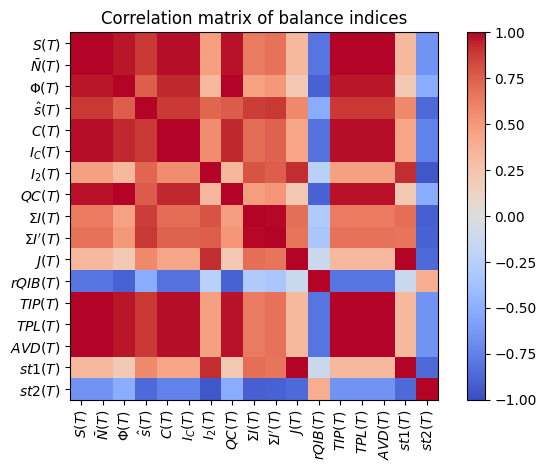

In [6]:
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(ticks=np.arange(len(labels)), labels=plotting_labels, rotation=90)
plt.yticks(ticks=np.arange(len(labels)), labels=plotting_labels)
plt.title('Correlation matrix of balance indices')
plt.tight_layout()
plt.show()

# Contrastingly, recover this matrix just using our basis representations

In [7]:
# First, we find the covariance matrix using src.tree_bstats.daughter_basis
daughter_cov = daughter_cov_matrix(n)

# Find the coefficients
coefficients = BalanceIndexCoefficients(n).get_daughter_coefficients()
labels, coefficients = zip(*coefficients.items())
coefficients = np.array(coefficients)

In [8]:
labels

('Sackin index',
 'Average leaf depth',
 'Total cophenetic index',
 '$\\hat{s}$-shape',
 'Colless index',
 'Corrected Colless index',
 'I2 index',
 'Quadratic Colless index',
 'Total I index',
 "Total I' index",
 'Rogers J index',
 'Rooted Quartet index for binary trees',
 'Total internal path length',
 'Total path length',
 'Average vertex depth',
 'stairs1 index',
 'stairs2 index')

In [9]:
coefficients.shape

(17, 64)

In [10]:
# The covariance matrix between indices is just the quadratic form of the coefficients multiplied by the covariance matrix
cov_matrix_basis = coefficients @ daughter_cov @ coefficients.T

# Use cov_matrix_basis to get the correlation matrix
corr_matrix_basis = cov_matrix_basis / np.sqrt(np.outer(np.diag(cov_matrix_basis), np.diag(cov_matrix_basis)))

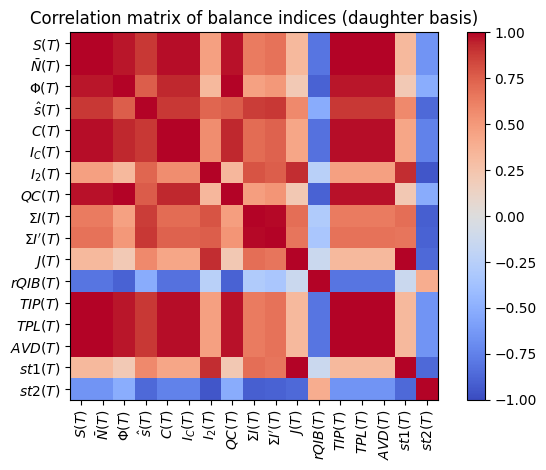

In [11]:
# Now we can compare the two correlation matrices
plt.imshow(corr_matrix_basis, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(ticks=np.arange(len(labels)), labels=plotting_labels, rotation=90)
plt.yticks(ticks=np.arange(len(labels)), labels=plotting_labels)
plt.title('Correlation matrix of balance indices (daughter basis)')
plt.tight_layout()
plt.show()

In [12]:
# Check that difference is small
np.max(np.abs(corr_matrix_basis - corr_matrix))

np.float64(2.220446049250313e-15)

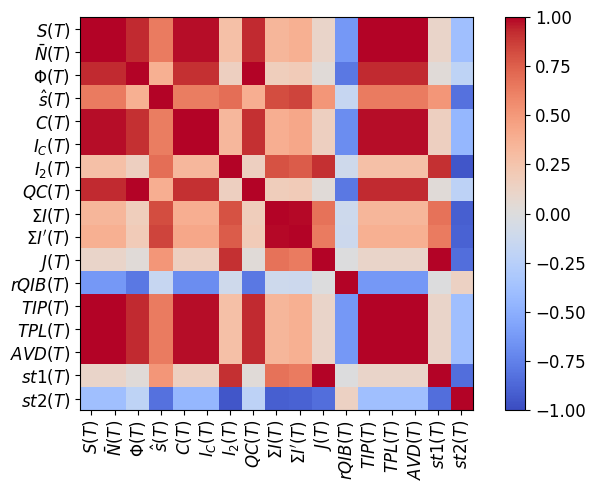

In [126]:
# Now repeat with n large (i.e., n = 200)

n = 100
daughter_cov = daughter_cov_matrix(n)

# Find the coefficients
coefficients = BalanceIndexCoefficients(n).get_daughter_coefficients()
labels, coefficients = zip(*coefficients.items())
coefficients = np.array(coefficients)
# The covariance matrix between indices is just the quadratic form of the coefficients multiplied by the covariance matrix
cov_matrix_basis = coefficients @ daughter_cov @ coefficients.T

# Use cov_matrix_basis to get the correlation matrix
corr_matrix_basis = cov_matrix_basis / np.sqrt(np.outer(np.diag(cov_matrix_basis), np.diag(cov_matrix_basis)))


# Plot the correlation matrix
plt.figure(figsize=(7, 5))
plt.imshow(corr_matrix_basis, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(ticks=np.arange(len(labels)), labels=plotting_labels, rotation=90)
plt.yticks(ticks=np.arange(len(labels)), labels=plotting_labels)
# plt.title('Correlation matrix of balance indices (daughter basis), n = ' + str(n))
plt.tight_layout()
plt.savefig(os.path.join(parent_dir, 'plots', 'correlation_matrix_daughter_basis_n100.png'))
plt.show()

In [131]:
corr_matrix_basis[2,:]

array([ 0.92310938,  0.92310938,  1.        ,  0.38045668,  0.90728762,
        0.90728762,  0.15048907,  0.99999168,  0.17010556,  0.19167899,
        0.02383233, -0.79155443,  0.92310938,  0.92310938,  0.92310938,
        0.02383233, -0.20902971])

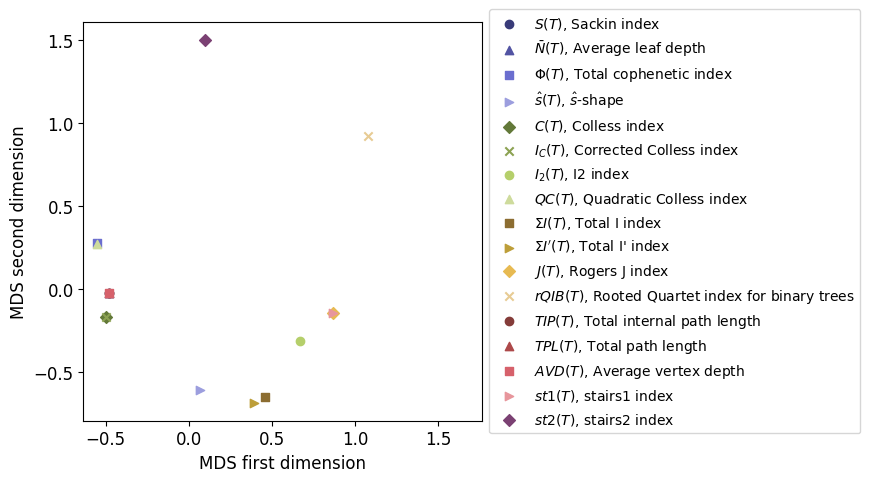

In [ ]:
# Use MDS to cluster indices based on correlation matrix

# Convert the correlation matrix into a distance matrix
dist_squares = 2 * (1 - corr_matrix_basis) 
zeroes_dist_squares = np.where(np.abs(dist_squares) < 2e-15, 0, dist_squares)
distance_matrix = np.sqrt(zeroes_dist_squares)

# Calculate the mds
mds = MDS(n_components=2, metric='precomputed', init = 'classical_mds')
coords = mds.fit_transform(distance_matrix)

# Now plot the points
plt.figure(figsize=(9,5))
# Same colors/markers as the means plot
colors = plt.color_sequences['tab20b']
markers = ['o', '^', 's', '>', 'D', 'x']

# Full labels (name and formula)
full_labels = []
for i in range(len(labels)):
    full_labels.append(plotting_labels[i] + ", " + labels[i] )

for i in range(len(coords)):
    plt.scatter(coords[i, 0], coords[i, 1], label = full_labels[i], 
                color = colors[i], marker = markers[i % len(markers)])
plt.xlabel("MDS first dimension", fontsize=12)
plt.ylabel("MDS second dimension", fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 10)
plt.axis('square')
plt.tight_layout()

plt.savefig(os.path.join(parent_dir, 'plots', 'MDS_plot_corr_matrix.png'))
plt.show()

# Paper figure w/correlations and MDS plot

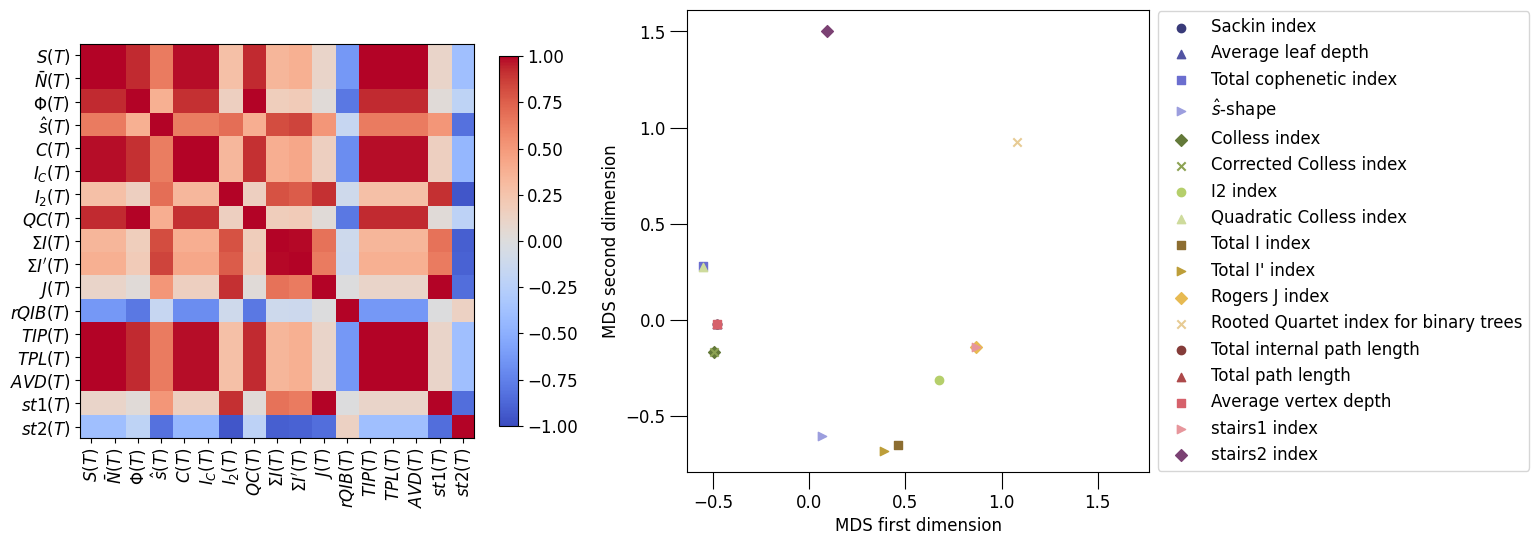

In [101]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 6), width_ratios=[1, 1])

# Left plot: correlation matrix
corr_plot = ax1.imshow(corr_matrix_basis, cmap='coolwarm', vmin=-1, vmax=1)

ax1.set_xticks(ticks=np.arange(len(labels)), labels=plotting_labels, fontsize=12, rotation=90)
ax1.set_yticks(ticks=np.arange(len(labels)), labels=plotting_labels, fontsize=12)
fig.colorbar(corr_plot, ax=ax1, shrink=0.8)

# Right plot: mds plot
colors = plt.color_sequences['tab20b']
markers = ['o', '^', 's', '>', 'D', 'x']

for i in range(len(coords)):
    ax2.scatter(coords[i, 0], coords[i, 1], label = labels[i], 
                color = colors[i], marker = markers[i % len(markers)])

ax2.set_xlabel("MDS first dimension", fontsize=12)
ax2.set_ylabel("MDS second dimension", fontsize=12)
ax2.tick_params(size=12)
ax2.axis('square')

ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12)